Biblioteka NetworkX udostępnia cztery podstawowe klasy grafów: `Graph`, `DiGraph`, `MultiGraph` oraz `MultiDiGraph`. Różnią się one tym, czy krawędzie mają kierunek i czy pomiędzy tymi samymi wierzchołkami może występować wiele krawędzi.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx

print("NetworkX", nx.__version__)

NetworkX 3.6.1


## Dodawanie krawędzi

We wszystkich czterech klasach metoda `add_edge(u, v)` dodaje krawędź pomiędzy wierzchołkami 'u' oraz 'v'. Nie dodajemy osobno wierzchołków, metoda tworzy je za nas. Atrybuty krawędzi (takie jak wagi, etykiety etc.) przekazujemy jako argumenty nazwane, na przykład `weight=3` albo `color="red"`. Wiele krawędzi można dodać za pomocą `add_edges_from()`.

### `Graph`

`Graph` jest grafem nieskierowanym bez krawędzi wielokrotnych. Ponowne dodanie tej samej krawędzi nie tworzy nowej krawędzi, lecz aktualizuje jej słownik atrybutów. Funkcja `add_edge(u, v)` oraz `add_edge(v, u)` będzie miała ten sam efekt.

In [ ]:
graph = nx.Graph() #tworzymy pusty graf nieskierowany
graph.add_edge("A", "B", weight=2) #tworzymy krawędź A--B z wagą 2
graph.add_edge("B", "A", color="turquoise") #dodajemy do krawędzi A-B atrybut

print("Wierzchołki:", list(graph.nodes))
print("Krawędzie:", list(graph.edges(data=True)))
print("Dane A--B:", dict(graph.edges["A", "B"]))
print("Wspólny słownik danych:", graph["A"]["B"] is graph["B"]["A"] )

Wierzchołki: ['A', 'B']
Krawędzie: [('A', 'B', {'weight': 2, 'color': 'turquoise'})]
Dane A--B: {'weight': 2, 'color': 'turquoise'}
Wspólny słownik danych: True


### `DiGraph`

`DiGraph` jest grafem skierowanym bez krawędzi wielokrotnych. Krawędzie `u → v` oraz `v → u` są różne. Ponowne dodanie `u → v` aktualizuje dane istniejącej krawędzi.

In [3]:
digraph = nx.DiGraph()
digraph.add_edge("A", "B", weight=2)
digraph.add_edge("B", "A", weight=5)
digraph.add_edge("A", "B", color="turquoise")

print("Wierzchołki:", list(digraph.nodes))
print("Krawędzie:", list(digraph.edges(data=True)))
print("Następnicy A:", list(digraph.successors("A")))
print("Poprzednicy A:", list(digraph.predecessors("A")))

Wierzchołki: ['A', 'B']
Krawędzie: [('A', 'B', {'weight': 2, 'color': 'turquoise'}), ('B', 'A', {'weight': 5})]
Następnicy A: ['B']
Poprzednicy A: ['B']


### `MultiGraph`

`MultiGraph` jest multigrafem nieskierowanym. Każde wywołanie `add_edge(u, v)` bez podanego klucza tworzy kolejną krawędź i zwraca jej utworzony automatycznie klucz. Podanie istniejącego klucza aktualizuje wskazaną krawędź. Można również używać własnych kluczy, na przykład `key="A1"`.

In [4]:
multigraph = nx.MultiGraph()
first_key = multigraph.add_edge("A", "B", route="lokalna")
second_key = multigraph.add_edge("A", "B", route="ekspresowa")
multigraph.add_edge("B", "A", key=first_key, color="turquoise")

print("Nadane klucze:", first_key, second_key)
print("Krawędzie:")
for u, v, key, data in multigraph.edges(keys=True, data=True):
    print(u, v, key, data)

Nadane klucze: 0 1
Krawędzie:
A B 0 {'route': 'lokalna', 'color': 'turquoise'}
A B 1 {'route': 'ekspresowa'}


### `MultiDiGraph`

`MultiDiGraph` łączy kierunek z możliwością przechowywania krawędzi równoległych. Klucze są lokalne dla uporządkowanej pary końców. Dlatego pierwsza krawędź `A → B` i pierwsza krawędź `B → A` mogą otrzymać ten sam klucz.

In [5]:
multidigraph = nx.MultiDiGraph()
forward_1 = multidigraph.add_edge("A", "B", route="pierwsza")
forward_2 = multidigraph.add_edge("A", "B", route="druga")
backward = multidigraph.add_edge("B", "A", route="powrotna")

print("Klucze A → B:", forward_1, forward_2)
print("Klucz B → A:", backward)
print("Krawędzie:", list(multidigraph.edges(keys=True, data=True)))

Klucze A → B: 0 1
Klucz B → A: 0
Krawędzie: [('A', 'B', 0, {'route': 'pierwsza'}), ('A', 'B', 1, {'route': 'druga'}), ('B', 'A', 0, {'route': 'powrotna'})]


## Jak NetworkX przechowuje krawędzie

Strukturę danych można schematycznie zapisać następująco:

| Klasa | Struktura sąsiedztwa | Wartość końcowa |
|---|---|---|
| `Graph` | `G.adj[u][v]` | słownik atrybutów |
| `DiGraph` | `G.succ[u][v]`, `G.pred[v][u]` | słownik atrybutów |
| `MultiGraph` | `G.adj[u][v][key]` | słownik atrybutów konkretnej krawędzi |
| `MultiDiGraph` | `G.succ[u][v][key]`, `G.pred[v][u][key]` | słownik atrybutów konkretnej krawędzi |

Przetestuj, doczytaj, czym są `G.adj`, `G.adj[v]`, `G.succ`, `G.succ[v]`, `G.pred[v]` dla odpowiednich przykładów. Zauważ, że dla DiGrafu mamy `G.succ[u][v] == G.pred[v][u]`.

## Dostęp do jednej krawędzi

Do tych samych danych mamy dostęp również za pomocą metody 'edges'. W `Graph` i `DiGraph` krawędź jest wyznaczona przez parę końców. W `MultiGraph` i `MultiDiGraph` trzeba dodatkowo podać jej klucz.

In [6]:
print(dict(graph.edges["A", "B"]))
print(dict(digraph.edges["A", "B"]))
print(dict(multigraph.edges["A", "B", first_key]))
print(dict(multidigraph.edges["A", "B", forward_2]))

{'weight': 2, 'color': 'turquoise'}
{'weight': 2, 'color': 'turquoise'}
{'route': 'lokalna', 'color': 'turquoise'}
{'route': 'druga'}


### Sam klucz nie wystarcza

Klucz multikrawędzi nie jest globalnym identyfikatorem. Ten sam klucz może pojawić się pomiędzy różnymi parami wierzchołków, a NetworkX nie utrzymuje dodatkowego indeksu `key → końce krawędzi`. Jeżeli znamy tylko klucz, musimy przejrzeć krawędzie.

In [7]:
roads = nx.MultiGraph()
roads.add_edge("Warszawa", "Łódź", key="A1", length=130)
roads.add_edge("Kraków", "Katowice", key="A1", length=80)

matches = [
    (u, v, key, data)
    for u, v, key, data in roads.edges(keys=True, data=True)
    if key == "A1"
]
matches

[('Warszawa', 'Łódź', 'A1', {'length': 130}),
 ('Kraków', 'Katowice', 'A1', {'length': 80})]

## Podstawy wizualizacji

Najprostsza funkcja `nx.draw()` jednocześnie wybiera położenia wierzchołków i rysuje graf za pomocą Matplotlib. Do szybkich eksperymentów wystarczy podać `with_labels=True`.

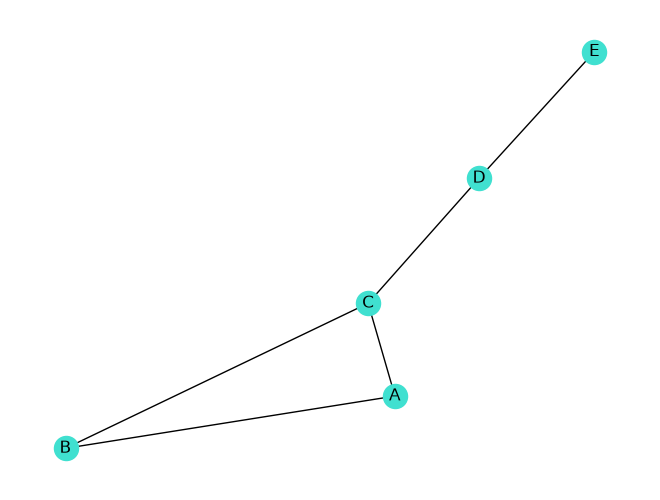

In [9]:
visual_graph = nx.Graph()
visual_graph.add_weighted_edges_from([
    ("A", "B", 2),
    ("A", "C", 4),
    ("B", "C", 1),
    ("C", "D", 3),
    ("D", "E", 2),
])

nx.draw(visual_graph, with_labels=True, node_color="turquoise")
plt.show()

### Pozycje wierzchołków

Funkcja `nx.draw()` może otrzymać w argumencie `pos` słownik, który każdemu wierzchołkowi przypisuje parę współrzędnych `(x, y)`. Dzięki temu sami ustalamy układ grafu, zamiast pozostawiać jego wyznaczenie bibliotece NetworkX. Współrzędne nie oznaczają pikseli ani konkretnych jednostek — ważne jest ich wzajemne położenie: większa wartość `x` przesuwa wierzchołek w prawo, a większa wartość `y` w górę.

In [ ]:
positions = {
    "A": (0, 1),
    "B": (-1, 0),
    "C": (1, 0),
    "D": (2, -1),
    "E": (3, 0),
}

nx.draw(
    visual_graph,
    pos=positions,
    with_labels=True,
    node_color="turquoise",
    edgecolors="#168C88",
    node_size=900,
)
plt.show()

Współrzędnych nie musimy wypisywać sami. Poniższe funkcje tworzą je automatycznie: `spring_layout()`, `planar_layout()`, `circular_layout()` i `shell_layout()`. Ustalenie `seed` pozwala odtwarzać ten sam układ losowy.

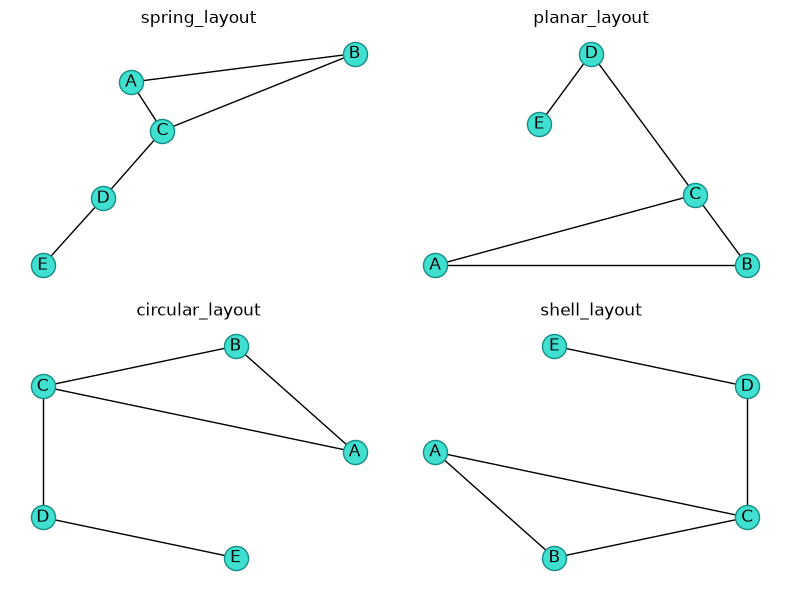

In [10]:
layouts = {
    "spring_layout": nx.spring_layout(visual_graph, seed=7),
    "planar_layout": nx.planar_layout(visual_graph),
    "circular_layout": nx.circular_layout(visual_graph),
    "shell_layout": nx.shell_layout(visual_graph),
}

fig, axes = plt.subplots(2, 2, figsize=(8, 6))
for ax, (name, positions) in zip(axes.flat, layouts.items()):
    nx.draw(
        visual_graph,
        positions,
        with_labels=True,
        node_color="turquoise",
        edgecolors="#168C88",
        ax=ax,
    )
    ax.set_title(name)
fig.tight_layout()
plt.show()

NetworkX zawiera również układy dostosowane do szczególnych sytuacji: `bipartite_layout()`, `multipartite_layout()` i `bfs_layout()`. Dostępne są też między innymi `kamada_kawai_layout()`, `spectral_layout()`, `spiral_layout()`, `random_layout()`, `forceatlas2_layout()` oraz `arf_layout()`. Niektóre z nich, w tym `kamada_kawai_layout()`, wymagają zainstalowania opcjonalnego pakietu SciPy.

### Dokładniejsze sterowanie rysunkiem

Funkcja `draw_networkx()` rysuje wierzchołki, krawędzie i etykiety. Gdy potrzebujemy większej kontroli, możemy wywołać osobno `draw_networkx_nodes()`, `draw_networkx_edges()`, `draw_networkx_labels()` oraz `draw_networkx_edge_labels()`.

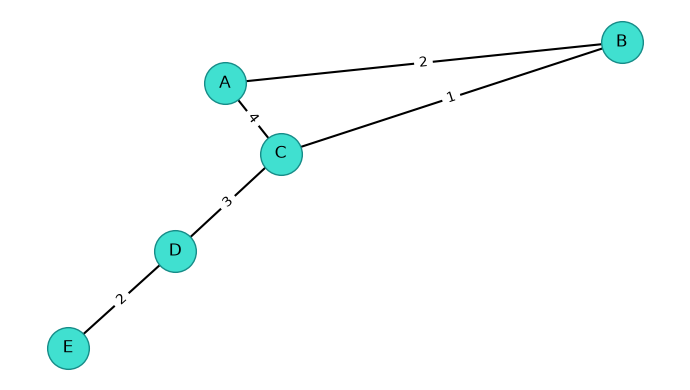

In [11]:
positions = nx.spring_layout(visual_graph, seed=7)
edge_labels = nx.get_edge_attributes(visual_graph, "weight")

fig, ax = plt.subplots(figsize=(7, 4))
nx.draw_networkx_nodes(
    visual_graph, positions, node_color="turquoise",
    edgecolors="#168C88", node_size=900, ax=ax,
)
nx.draw_networkx_edges(visual_graph, positions, width=1.5, ax=ax)
nx.draw_networkx_labels(visual_graph, positions, ax=ax)
nx.draw_networkx_edge_labels(
    visual_graph, positions, edge_labels=edge_labels, ax=ax,
)
ax.set_axis_off()
fig.tight_layout()
plt.show()

Dla grafów skierowanych `draw_networkx_edges()` rysuje groty strzałek. W multigrafach krawędzie równoległe można rozsunąć za pomocą argumentu `connectionstyle`, na przykład `"arc3,rad=0.15"`. NetworkX udostępnia także skróty takie jak `draw_spring()`, `draw_circular()`, `draw_shell()`, `draw_kamada_kawai()` i `draw_planar()`, które od razu stosują odpowiadający im układ.